# การวิเคราะห์และจัดกลุ่มรูปแบบความนิยมของเพลงบนชาร์ต Spotify ประเทศไทยด้วย Machine Learning
**Thailand Spotify Chart Analysis Using Machine Learning**

Notebook นี้เรียก `run_pipeline()` ตัวเดียวกับคำสั่ง `python -m thai_chart_ml run` ผลจึงตรงกันเมื่อใช้ค่าตั้งต้นเดียวกัน
- ถ้ามี `data/raw/charts.csv` จะใช้ข้อมูลจริง
- ถ้าไม่มี จะใช้ **ข้อมูลจำลอง** และทุกตารางในหน้านี้ไม่ใช่ผลของชาร์ตไทย

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display
from thai_chart_ml.config import PipelineConfig
from thai_chart_ml.pipeline import run_pipeline
from thai_chart_ml.recommend import recommend, resolve_song, SearchError
pd.set_option("display.max_colwidth", 60)

## 1) ตั้งค่า
ค่าเริ่มต้นเหมือน CLI: ย้อนหลัง 12 เดือนจากวันล่าสุด, k = 2–8, random_state = 42, เพลงตั้งต้น 10 เพลง

In [2]:
cfg = PipelineConfig(
    start_date=None,   # เช่น "2021-01-01"
    end_date=None,     # เช่น "2021-12-31"
    k_min=2, k_max=8,
)
result = run_pipeline(cfg)
s = result["summary"]
if s["warning"]:
    display(Markdown(f"> ⚠️ **{s['warning']}**"))
display(Markdown(f"**แหล่งข้อมูล:** `{s['data_source']}` · ผลลัพธ์อยู่ที่ `{s['output_dir']}`"))

[ข้อมูล] ไม่พบไฟล์ charts.csv: C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\data\raw\charts.csv
  -> ดาวน์โหลดจาก https://www.kaggle.com/datasets/dhruvildave/spotify-charts
  -> แล้ววางไฟล์ไว้ที่ C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\data\raw\charts.csv
[ข้อมูล] *** ใช้ข้อมูลจำลองสำหรับทดสอบ: ผลลัพธ์นี้มาจากข้อมูลจำลอง (synthetic) เพื่อทดสอบโค้ดเท่านั้น ไม่ใช่ผลของชาร์ต Spotify ประเทศไทย ***


[ข้อมูล] แหล่งข้อมูล: synthetic | ผลลัพธ์จะอยู่ที่ C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\outputs\synthetic
[data] chunk 1: อ่านแล้ว 63,184 แถว, พบที่ตรงเงื่อนไขสะสม 63,084


[data] บันทึกข้อมูลที่กรองแล้ว 63,084 แถว -> C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\data\synthetic\processed\thailand_top200_filtered.csv
[ข้อมูล] ช่วงวันจริง 2020-11-25 ถึง 2021-11-24 | มีข้อมูล 364 วัน จาก 365 วัน | ขาด 1 วัน


[ข้อมูล] ทำความสะอาด: 60,212 -> 60,212 แถว (ไม่มี track_id 0, ซ้ำ 0, อันดับขัดแย้ง 0 กลุ่ม)


[ข้อมูล] เพลงทั้งหมด 320 เพลง | จับคู่ข้อมูลเสียงได้ 147 เพลง (45.94%)
[model] k=2: silhouette=0.3213 ขนาดกลุ่ม=[161, 159]
[model] k=3: silhouette=0.3267 ขนาดกลุ่ม=[127, 103, 90]
[model] k=4: silhouette=0.3629 ขนาดกลุ่ม=[121, 79, 76, 44]
[model] k=5: silhouette=0.4017 ขนาดกลุ่ม=[86, 83, 72, 44, 35]


[model] k=6: silhouette=0.4148 ขนาดกลุ่ม=[76, 73, 50, 45, 44, 32]
[model] k=7: silhouette=0.4029 ขนาดกลุ่ม=[71, 67, 50, 45, 32, 29, 26]
[model] k=8: silhouette=0.3925 ขนาดกลุ่ม=[72, 46, 44, 38, 37, 30, 28, 25]
[model] เลือก k=6 (Silhouette=0.4148)


... (4,059 outputs left out)

findfont: Font family 'Noto Sans Thai' not found.


[done] บันทึกผลทั้งหมดที่ C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\outputs\synthetic


> ⚠️ **ผลลัพธ์นี้มาจากข้อมูลจำลอง (synthetic) เพื่อทดสอบโค้ดเท่านั้น ไม่ใช่ผลของชาร์ต Spotify ประเทศไทย**

**แหล่งข้อมูล:** `synthetic` · ผลลัพธ์อยู่ที่ `C:\Users\Administrator\Desktop\thailand-spotify-chart-ml\outputs\synthetic`

## 2) ช่วงวันและคุณภาพข้อมูล

In [3]:
dw = result["date_info"]
display(pd.Series({k: v for k, v in dw.items() if k != "missing_days"}, name="ค่า").to_frame())
print("วันที่ข้อมูลขาด:", dw["missing_days"][:30])
display(pd.Series({k: v for k, v in result["clean_stats"].items() if k != "rank_conflict_examples"}, name="จำนวน").to_frame())

,ค่า
data_available_from,2020-10-01
data_available_to,2021-11-24
requested_start,2020-11-25
requested_end,2021-11-24
default_12_month_window,True
actual_first_date,2020-11-25
actual_last_date,2021-11-24
calendar_days_in_window,365
days_with_data,364
missing_days_count,1


วันที่ข้อมูลขาด: ['2021-04-19']


,จำนวน
rows_in_window,60212
dropped_no_track_id,0
dropped_invalid_rank,0
dropped_exact_duplicates,0
rank_conflict_groups,0
dropped_conflicting_rank_rows,0
rows_sharing_date_and_rank,0
rows_after_cleaning,60212
total_rows_removed,0


## 3) การจับคู่ข้อมูลเสียง (left join ด้วย track_id)

In [4]:
a = result["audio_stats"]
display(pd.Series({k: v for k, v in a.items() if k != "message"}, name="ค่า").to_frame())

,ค่า
available,True
rows_in_file,314
rows_with_track_id,314
unique_track_ids,292
songs,320
matched,147
matched_pct,45.94
unmatched,173


## 4) Silhouette Score และขนาดกลุ่มของแต่ละ k

,k,silhouette,inertia,cluster_sizes,min_cluster_size,status
0,2,0.3213,848.27,"[161, 159]",159,tested
1,3,0.3267,650.47,"[127, 103, 90]",90,tested
2,4,0.3629,479.08,"[121, 79, 76, 44]",44,tested
3,5,0.4017,340.80,"[86, 83, 72, 44, 35]",35,tested
4,6,0.4148,291.95,"[76, 73, 50, 45, 44, 32]",32,tested
5,7,0.4029,258.54,"[71, 67, 50, 45, 32, 29, 26]",26,tested
6,8,0.3925,223.71,"[72, 46, 44, 38, 37, 30, 28, 25]",25,tested


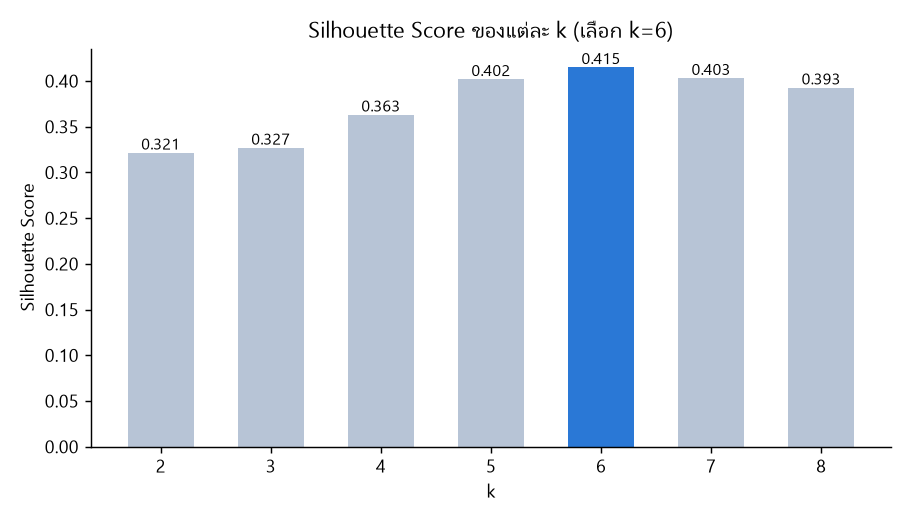

In [5]:
display(result["k_scores"])
display(Image(str(result["out_dir"] / "k_silhouette.png")))

## 5) โปรไฟล์ของแต่ละกลุ่ม (จำนวนเพลงและค่ากลางของคุณลักษณะ)

,cluster,cluster_name,n_songs,median_best_rank,median_median_rank,median_days_on_chart,median_days_to_peak,mean_best_rank,mean_median_rank,mean_days_on_chart,mean_days_to_peak,share_pct
0,0,อันดับสูงสุดระดับกลาง · ติดชาร์ตนาน · ถึงจุดสูงสุดเร็ว,76,10.0,78.75,341.5,2.5,11.57,76.68,318.50,7.47,23.75
1,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,73,6.0,28.00,75.0,8.0,8.96,29.73,86.16,9.75,22.81
2,2,อันดับสูงสุดไม่สูง · ติดชาร์ตปานกลาง · ค่อยๆ ไต่ขึ้น,50,29.0,127.75,199.0,4.5,28.52,130.30,168.26,4.40,15.62
3,3,ขึ้นอันดับสูง · ติดชาร์ตช่วงสั้น · ถึงจุดสูงสุดเร็ว,45,3.0,145.00,123.0,2.0,4.98,140.98,121.04,1.76,14.06
4,4,อันดับสูงสุดระดับกลาง · ติดชาร์ตปานกลาง · ค่อยๆ ไต่ขึ้น,44,6.0,51.00,183.5,47.0,6.34,51.98,192.93,47.73,13.75
5,5,อันดับสูงสุดไม่สูง · ติดชาร์ตปานกลาง · ถึงจุดสูงสุดเร็ว,32,56.0,128.50,219.0,0.0,56.34,128.17,230.22,0.16,10.00


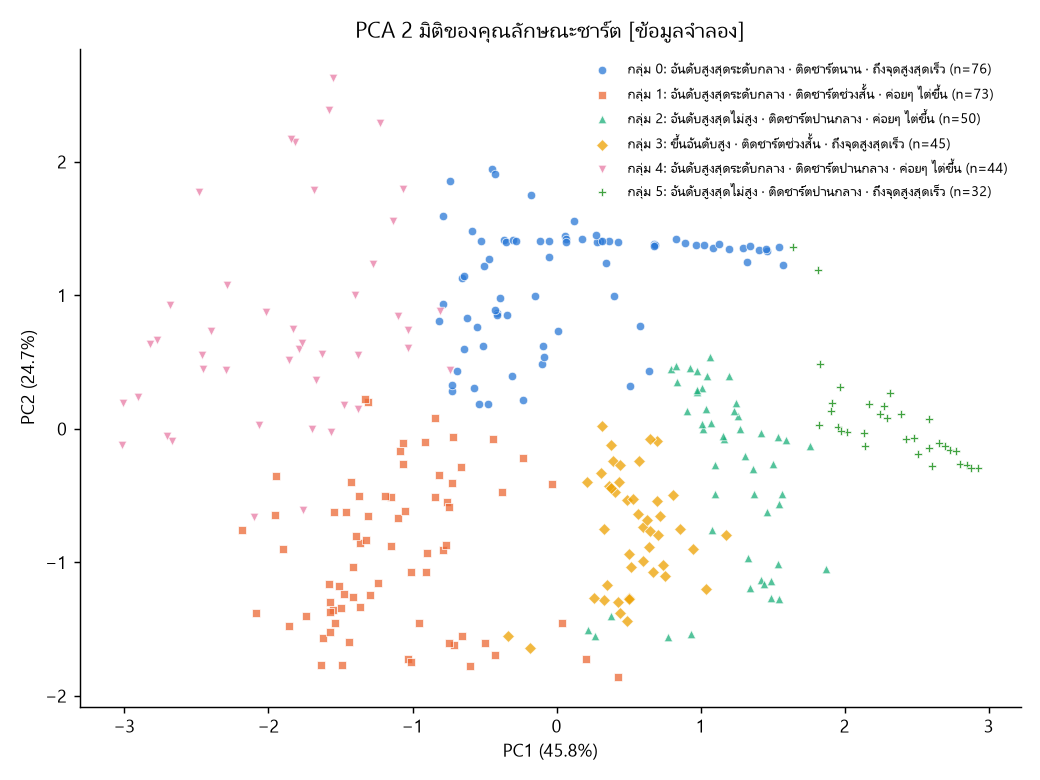

In [6]:
display(result["profiles"])
display(Image(str(result["out_dir"] / "pca_clusters.png")))

## 6) ข้อมูลเสียงประกอบ (เฉพาะเพลงที่จับคู่ได้ พร้อม n ของแต่ละกลุ่ม)

,cluster,cluster_name,n_songs,n_audio_matched,matched_pct,mean_danceability,mean_energy,mean_acousticness,mean_valence,mean_tempo
0,0,อันดับสูงสุดระดับกลาง · ติดชาร์ตนาน · ถึงจุดสูงสุดเร็ว,76,35,46.05,0.5967,0.6231,0.3300,0.5501,118.3400
1,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,73,33,45.21,0.5967,0.5812,0.3868,0.4899,129.2424
2,2,อันดับสูงสุดไม่สูง · ติดชาร์ตปานกลาง · ค่อยๆ ไต่ขึ้น,50,26,52.00,0.5983,0.4789,0.4115,0.5127,127.4769
3,3,ขึ้นอันดับสูง · ติดชาร์ตช่วงสั้น · ถึงจุดสูงสุดเร็ว,45,17,37.78,0.5943,0.6052,0.4509,0.5741,106.6706
4,4,อันดับสูงสุดระดับกลาง · ติดชาร์ตปานกลาง · ค่อยๆ ไต่ขึ้น,44,20,45.45,0.5795,0.5562,0.4189,0.4748,118.8550
5,5,อันดับสูงสุดไม่สูง · ติดชาร์ตปานกลาง · ถึงจุดสูงสุดเร็ว,32,16,50.00,0.5172,0.5809,0.3390,0.4891,121.0625


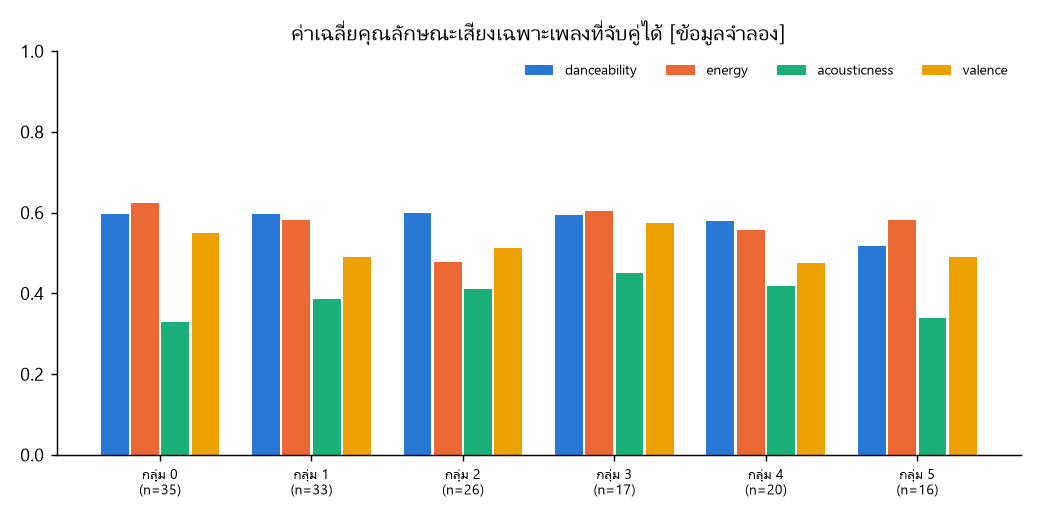

In [7]:
display(result["audio_profiles"])
display(Image(str(result["out_dir"] / "audio_by_cluster.png")))

## 7) ค้นหาเพลงและแนะนำ 5 เพลง
เปลี่ยน `query` เป็นชื่อเพลงที่ต้องการ ถ้าชื่อซ้ำจะแสดง Track ID ให้เลือกแล้วใส่ใน `track_id`

In [8]:
songs = result["songs"]
query = songs.sort_values("best_rank").iloc[0]["title"]   # ตัวอย่าง: เพลงที่ขึ้นอันดับสูงสุด
track_id = None
try:
    song = resolve_song(songs, query, track_id)
    print(f"เพลงตั้งต้น: {song.title} — {song.artist} [{song.track_id}] กลุ่ม {song.cluster}: {song.cluster_name}")
    display(recommend(songs, song.track_id, 5))
except SearchError as e:
    print(e)

เพลงตั้งต้น: Synthetic Song 036 — Synthetic Artist 25 [5IfijoySjTneAAvIDAdn1A] กลุ่ม 1: อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น


,track_id,title,artist,similarity,cluster,cluster_name,best_rank,median_rank,days_on_chart,days_to_peak
0,psfzRV0veJ7lEuwn5Krl8V,Synthetic Song 315,Synthetic Artist 44,0.9980,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,3,43.0,15,1
1,yiAmP4ZHpOZIYbyYTwEIYF,Synthetic Song 217,Synthetic Artist 23,0.9699,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,9,59.0,13,1
2,6NoPeO0D6StPAhic8ctFhg,Synthetic Song 074,Synthetic Artist 16,0.9694,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,1,71.5,26,2
3,pcExy6jl792cJZ6TVPAoup,Synthetic Song 205,Synthetic Artist 27,0.9530,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,3,7.0,12,1
4,kfrXzwQzzLmHaVTe6fJsU1,Synthetic Song 311,Synthetic Artist 36,0.9468,1,อันดับสูงสุดระดับกลาง · ติดชาร์ตช่วงสั้น · ค่อยๆ ไต่ขึ้น,1,1.0,12,1


## 8) ประเมินผลเทียบกับการสุ่ม (เชิงสำรวจ)
ตัวชี้วัด `trajectory_mad` คำนวณจากเส้นอันดับรายวัน ไม่ใช่คะแนน cosine ที่ใช้แนะนำ แต่ยังมาจากข้อมูลชาร์ตชุดเดียวกัน จึงเป็นการตรวจเชิงสำรวจ ยังไม่มีคะแนนจากผู้ประเมิน

,ค่า
type,exploratory (ยังไม่มีคะแนนจากผู้ประเมิน)
n_seeds,10
seed_selection,numpy default_rng(42) เลือกจาก track_id ที่เรียงแล้ว
metric,trajectory_mad: ผลต่างอันดับรายวันเฉลี่ย 90 วันแรกหลังพบ...
random_baseline,สุ่ม 5 เพลง x 100 ครั้งต่อเพลงตั้งต้น
mean_rec_trajectory_mad,8.8
mean_random_trajectory_mad,43.0
seeds_rec_better_than_random,10
audio_pairs_available,16
note,ตัวชี้วัดมาจากข้อมูลชาร์ตชุดเดียวกับคุณลักษณะที่ใช้แนะนำ...


,seed_track_id,seed_title,rec_trajectory_mad,random_trajectory_mad,rec_same_cluster_pct,rec_audio_distance,random_audio_distance,rec_audio_pairs,rec_better_than_random
0,zQuRiUbPFsq6AzyVcLTK0m,Synthetic Song 246,8.58,34.00,100.0,NaN,NaN,0,True
1,kuTssKr82G5R0gi9WYA6dr,Synthetic Song 188,22.03,34.89,100.0,3.739,3.311,2,True
2,6suVAlmiYI4xHG6r1kq608,Synthetic Song 071,7.30,40.76,100.0,3.780,3.535,3,True
3,dPI1af7W2pkAFEn3z5dkya,Synthetic Song 016,3.91,44.89,100.0,NaN,NaN,0,True
4,QZK2d2W7JDPJesQeqgmULF,Synthetic Song 289,12.24,43.61,80.0,3.708,2.918,2,True
5,QPpgsNe5muFCvNQtSLjKKx,Synthetic Song 290,11.92,42.33,60.0,2.510,3.219,2,True
6,gita8zv1NyZ3vCvB003PMi,Synthetic Song 171,5.52,39.76,100.0,3.585,3.115,3,True
7,7KUumWkFGDF4tFbf8zGD9p,Synthetic Song 125,7.25,65.62,100.0,NaN,NaN,0,True
8,EeiLoHRCaaSv0h3BSiEeoy,Synthetic Song 194,6.13,38.61,60.0,NaN,NaN,0,True
9,rhZxB4zVC59yvlFSFx7ZHr,Synthetic Song 111,3.14,45.48,100.0,2.043,2.461,4,True


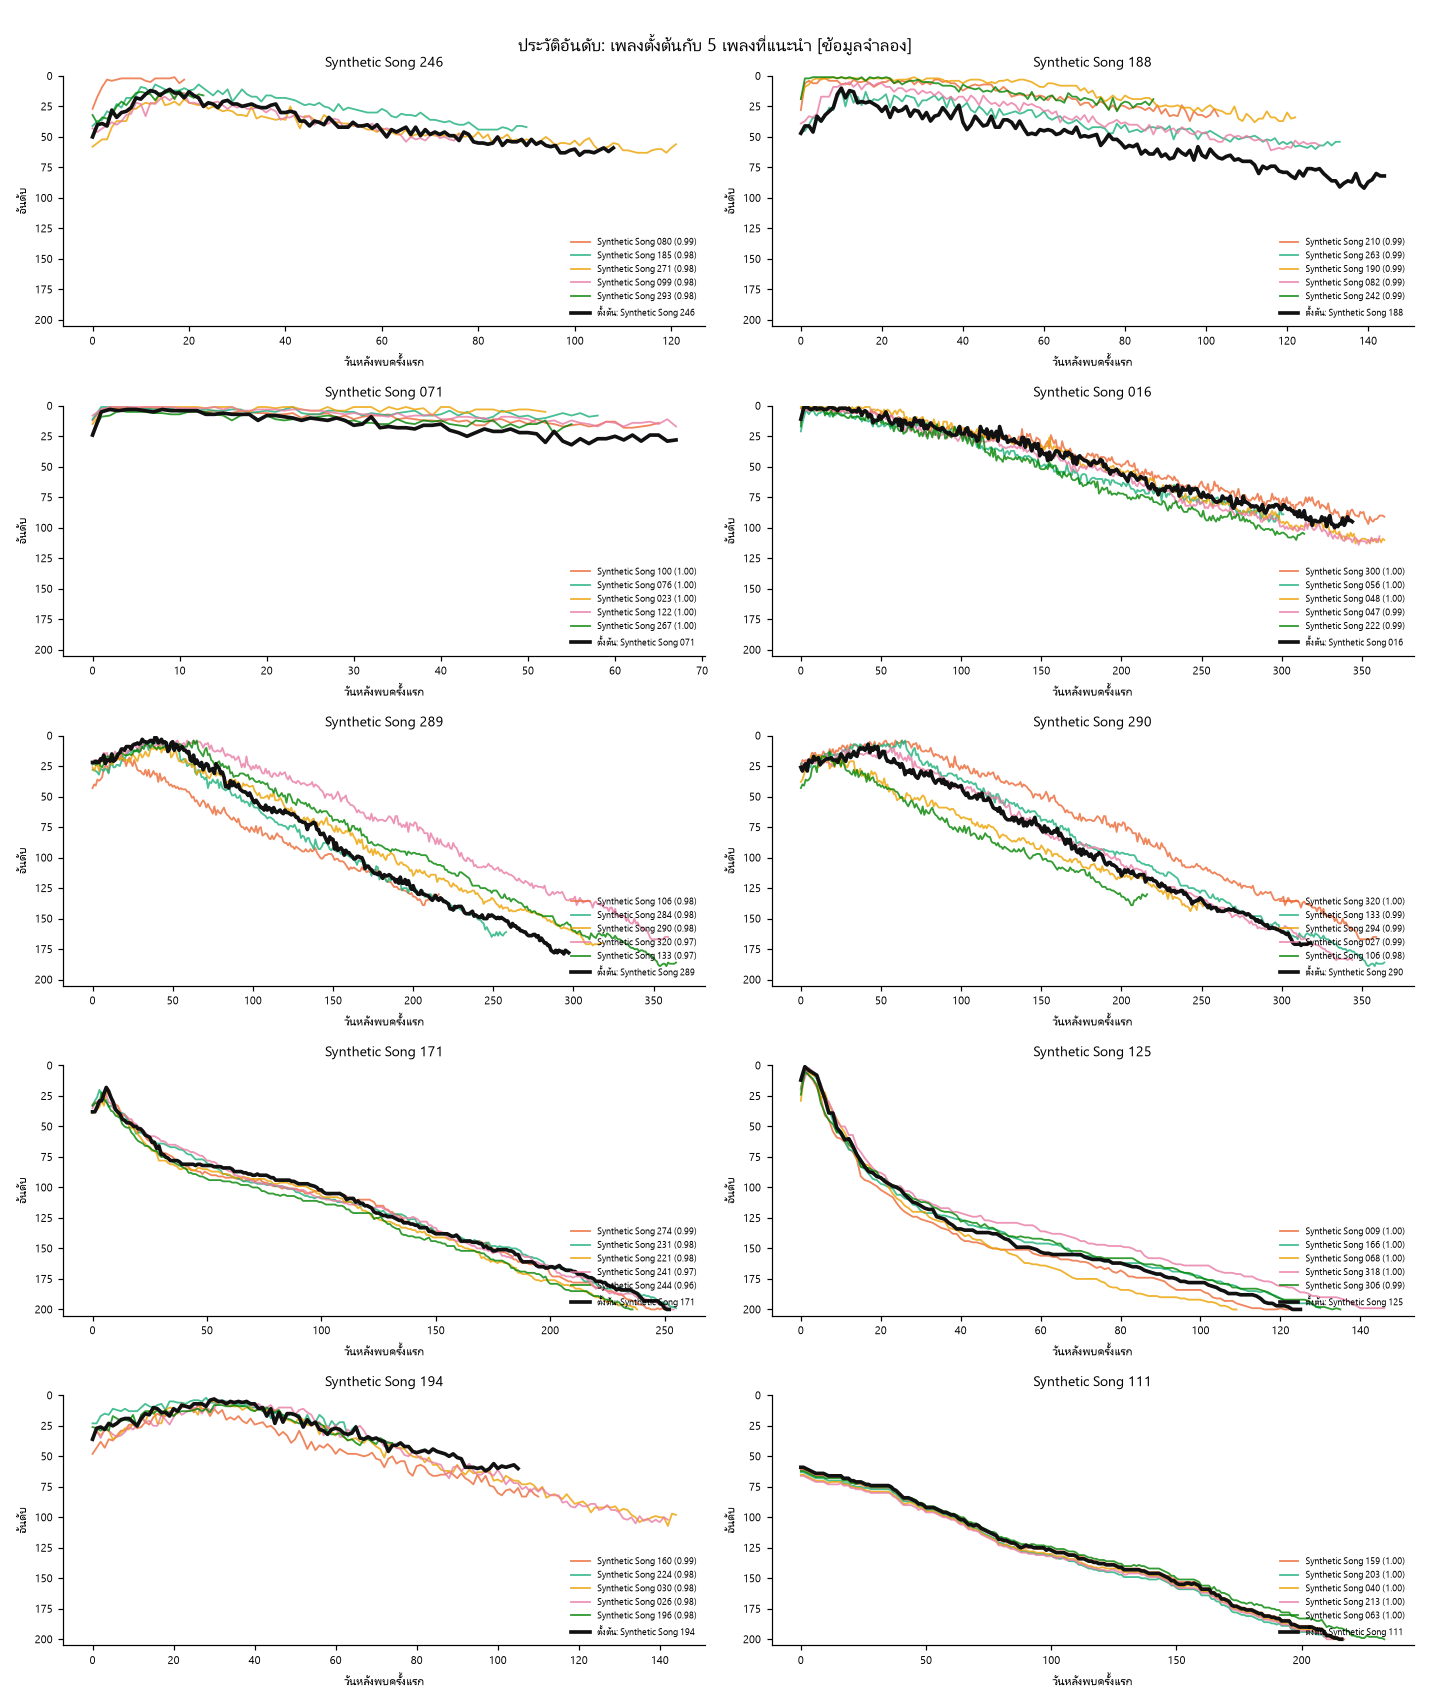

In [9]:
display(pd.Series(result["eval_summary"], name="ค่า").to_frame())
display(result["eval"])
display(Image(str(result["out_dir"] / "rank_history_samples.png")))